# Manuscript Figure Generation

This notebook generates all main-text figures for the PEARL TB screening manuscript.

**Figures produced:**
- Figure 1: Calibration (Figure 1 style from manuscript)
- Figure 2: Projected trajectories (baseline vs scenario_3)
- Figure 3: Sensitivity analysis (hard-to-reach population)
- Figure 4: Screening algorithms and coverage comparison

All figures saved in high-resolution PNG and PDF format.

In [1]:
# Import standard libraries
from pathlib import Path
from math import ceil
import numpy as np
import pandas as pd
import yaml

# Import scientific/plotting
import arviz as az
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.gridspec as gridspec

# Import project modules
from tbh.paths import REPO_ROOT_PATH
import tbh.plotting as pl

from importlib import reload

# Configure matplotlib
plt.style.use("seaborn-v0_8-white")
text_color = "#1f1f1f"
plt.rcParams.update({
    "font.family": "Helvetica",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.5,
    "legend.frameon": False,
    "legend.fontsize": 7,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "text.color": text_color,
    "axes.labelcolor": text_color,
    "axes.titlecolor": text_color,
    "xtick.color": text_color,
    "ytick.color": text_color,
    "axes.edgecolor": text_color,
})

print("Imports successful")

Imports successful


## Configuration

In [2]:
# Set paths
BASE_DIR = REPO_ROOT_PATH / "remote_cluster" / "outputs" / "59293003_longer_runs"
SA_BASE_DIR = REPO_ROOT_PATH / "remote_cluster" / "outputs" / "59223189_sas"

OUTPUT_DIR = REPO_ROOT_PATH / "notebooks" / "manuscript_figs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Base-case configuration for main text
BASE_CASE_REL_SUS = 1.5
BASE_CASE_REG = 1.0

# Scenario names for labeling
SC_NAMES_CUSTOM = {
    'baseline': 'No screening',
    'scenario_1': 'PEARL / 65%',
    'scenario_2': 'PEARL / 75%',
    'scenario_3': 'PEARL algorithm at 85% coverage',
    'scenario_6': 'CXR-TST / 65%',
    'scenario_7': 'CXR-TST / 75%',
    'scenario_8': 'CXR-TST / 85%',
    'scenario_16': 'CXR / 65%',
    'scenario_17': 'CXR / 75%',
    'scenario_18': 'CXR / 85%'
}

# Figure-specific outputs
TRAJECTORY_OUTPUTS = [
    "tb_incidence_per100k",
    "viable_tbi_prevalence_perc",
    "tb_prevalence_per100k",
    "tb_mortality_per100k",
]

print(f"Output directory: {OUTPUT_DIR}")
print(f"Base case: rel_sus={BASE_CASE_REL_SUS}, reg={BASE_CASE_REG}")

Output directory: /Users/rrag0004/Documents/Code/kiribati_tb_modelling/notebooks/manuscript_figs
Base case: rel_sus=1.5, reg=1.0


## Load task data

In [3]:
# Scan directory for completed tasks
task_dirs = sorted([p for p in BASE_DIR.iterdir() if p.is_dir()])

records = []
for task_dir in task_dirs:
    files = [x for x in task_dir.iterdir() if x.is_file()]
    names = {f.name for f in files}
    
    has_idata = "idata.nc" in names
    has_details = "details.yaml" in names
    
    if len(files) == 0:
        status = "empty"
    elif has_details:
        status = "completed"
    elif has_idata:
        status = "partial"
    else:
        status = "failed"
    
    records.append({
        "task": task_dir.name,
        "task_path": task_dir,
        "n_files": len(files),
        "status": status,
    })

status_df = pd.DataFrame(records)
completed_df = status_df.loc[status_df["status"] == "completed"].copy()
print(f"Found {len(completed_df)} completed tasks")

Found 16 completed tasks


In [4]:
# Load configuration map for task parameters
config_map_path = BASE_DIR / "task_config_map.yaml"
with open(config_map_path, "r") as f:
    raw_task_config_map = yaml.safe_load(f)

config_source = raw_task_config_map.get("tasks", raw_task_config_map) if isinstance(raw_task_config_map, dict) else raw_task_config_map
task_to_config = config_source.get("task_to_config", {}) if isinstance(config_source, dict) else {}

def get_task_config(task_name):
    task_num = int(task_name.split("_")[1])
    return task_to_config.get(task_num, task_to_config.get(str(task_num)))

completed_df["task_config"] = completed_df["task"].apply(get_task_config)
print("Task configurations loaded")

Task configurations loaded


In [5]:
# Load base-case task bundle
def find_task_row(df, rel_sus=None, reg=None):
    x = df.copy()
    x["rel_sus_unreachable"] = pd.to_numeric(
        x["task_config"].apply(lambda d: d.get("rel_sus_unreachable") if isinstance(d, dict) else np.nan),
        errors="coerce",
    )
    x["clinical_regression_rate"] = pd.to_numeric(
        x["task_config"].apply(lambda d: d.get("clinical_regression_rate") if isinstance(d, dict) else np.nan),
        errors="coerce",
    )
    
    if rel_sus is not None:
        x = x[np.isclose(x["rel_sus_unreachable"], rel_sus)]
    if reg is not None:
        x = x[np.isclose(x["clinical_regression_rate"], reg)]
    
    if x.empty:
        raise ValueError(f"No task found for rel_sus={rel_sus}, reg={reg}")
    
    return x.sort_values("task").iloc[0]

base_task_row = find_task_row(completed_df, rel_sus=BASE_CASE_REL_SUS, reg=BASE_CASE_REG)
base_task_path = Path(base_task_row["task_path"])
base_task_name = base_task_row["task"]

print(f"Base case task: {base_task_name}")

# Load uncertainty dataframes for scenarios
unc_bundle = pl.load_uncertainty_outputs_for_task(base_task_path, ["baseline", "scenario_3"])
unc_baseline = unc_bundle["baseline"]
unc_scenario3 = unc_bundle["scenario_3"]

print("Base-case uncertainty data loaded")

Base case task: task_6
Base-case uncertainty data loaded


In [6]:
# Task path selected; figure functions will build required model/data objects on demand.
print("Task ready for figure generation")

Task ready for figure generation


## Figure 1: Model Structure and Calibration

In [7]:
posterior_list = [
    "rel_sus_children",
    "breakdown_rate",
    "clearance_rate",
    "clinical_progression_rate",
    "infectiousness_gain_rate",
    "recent_detection_rate",
    "prev_se_cleared_tst"
]

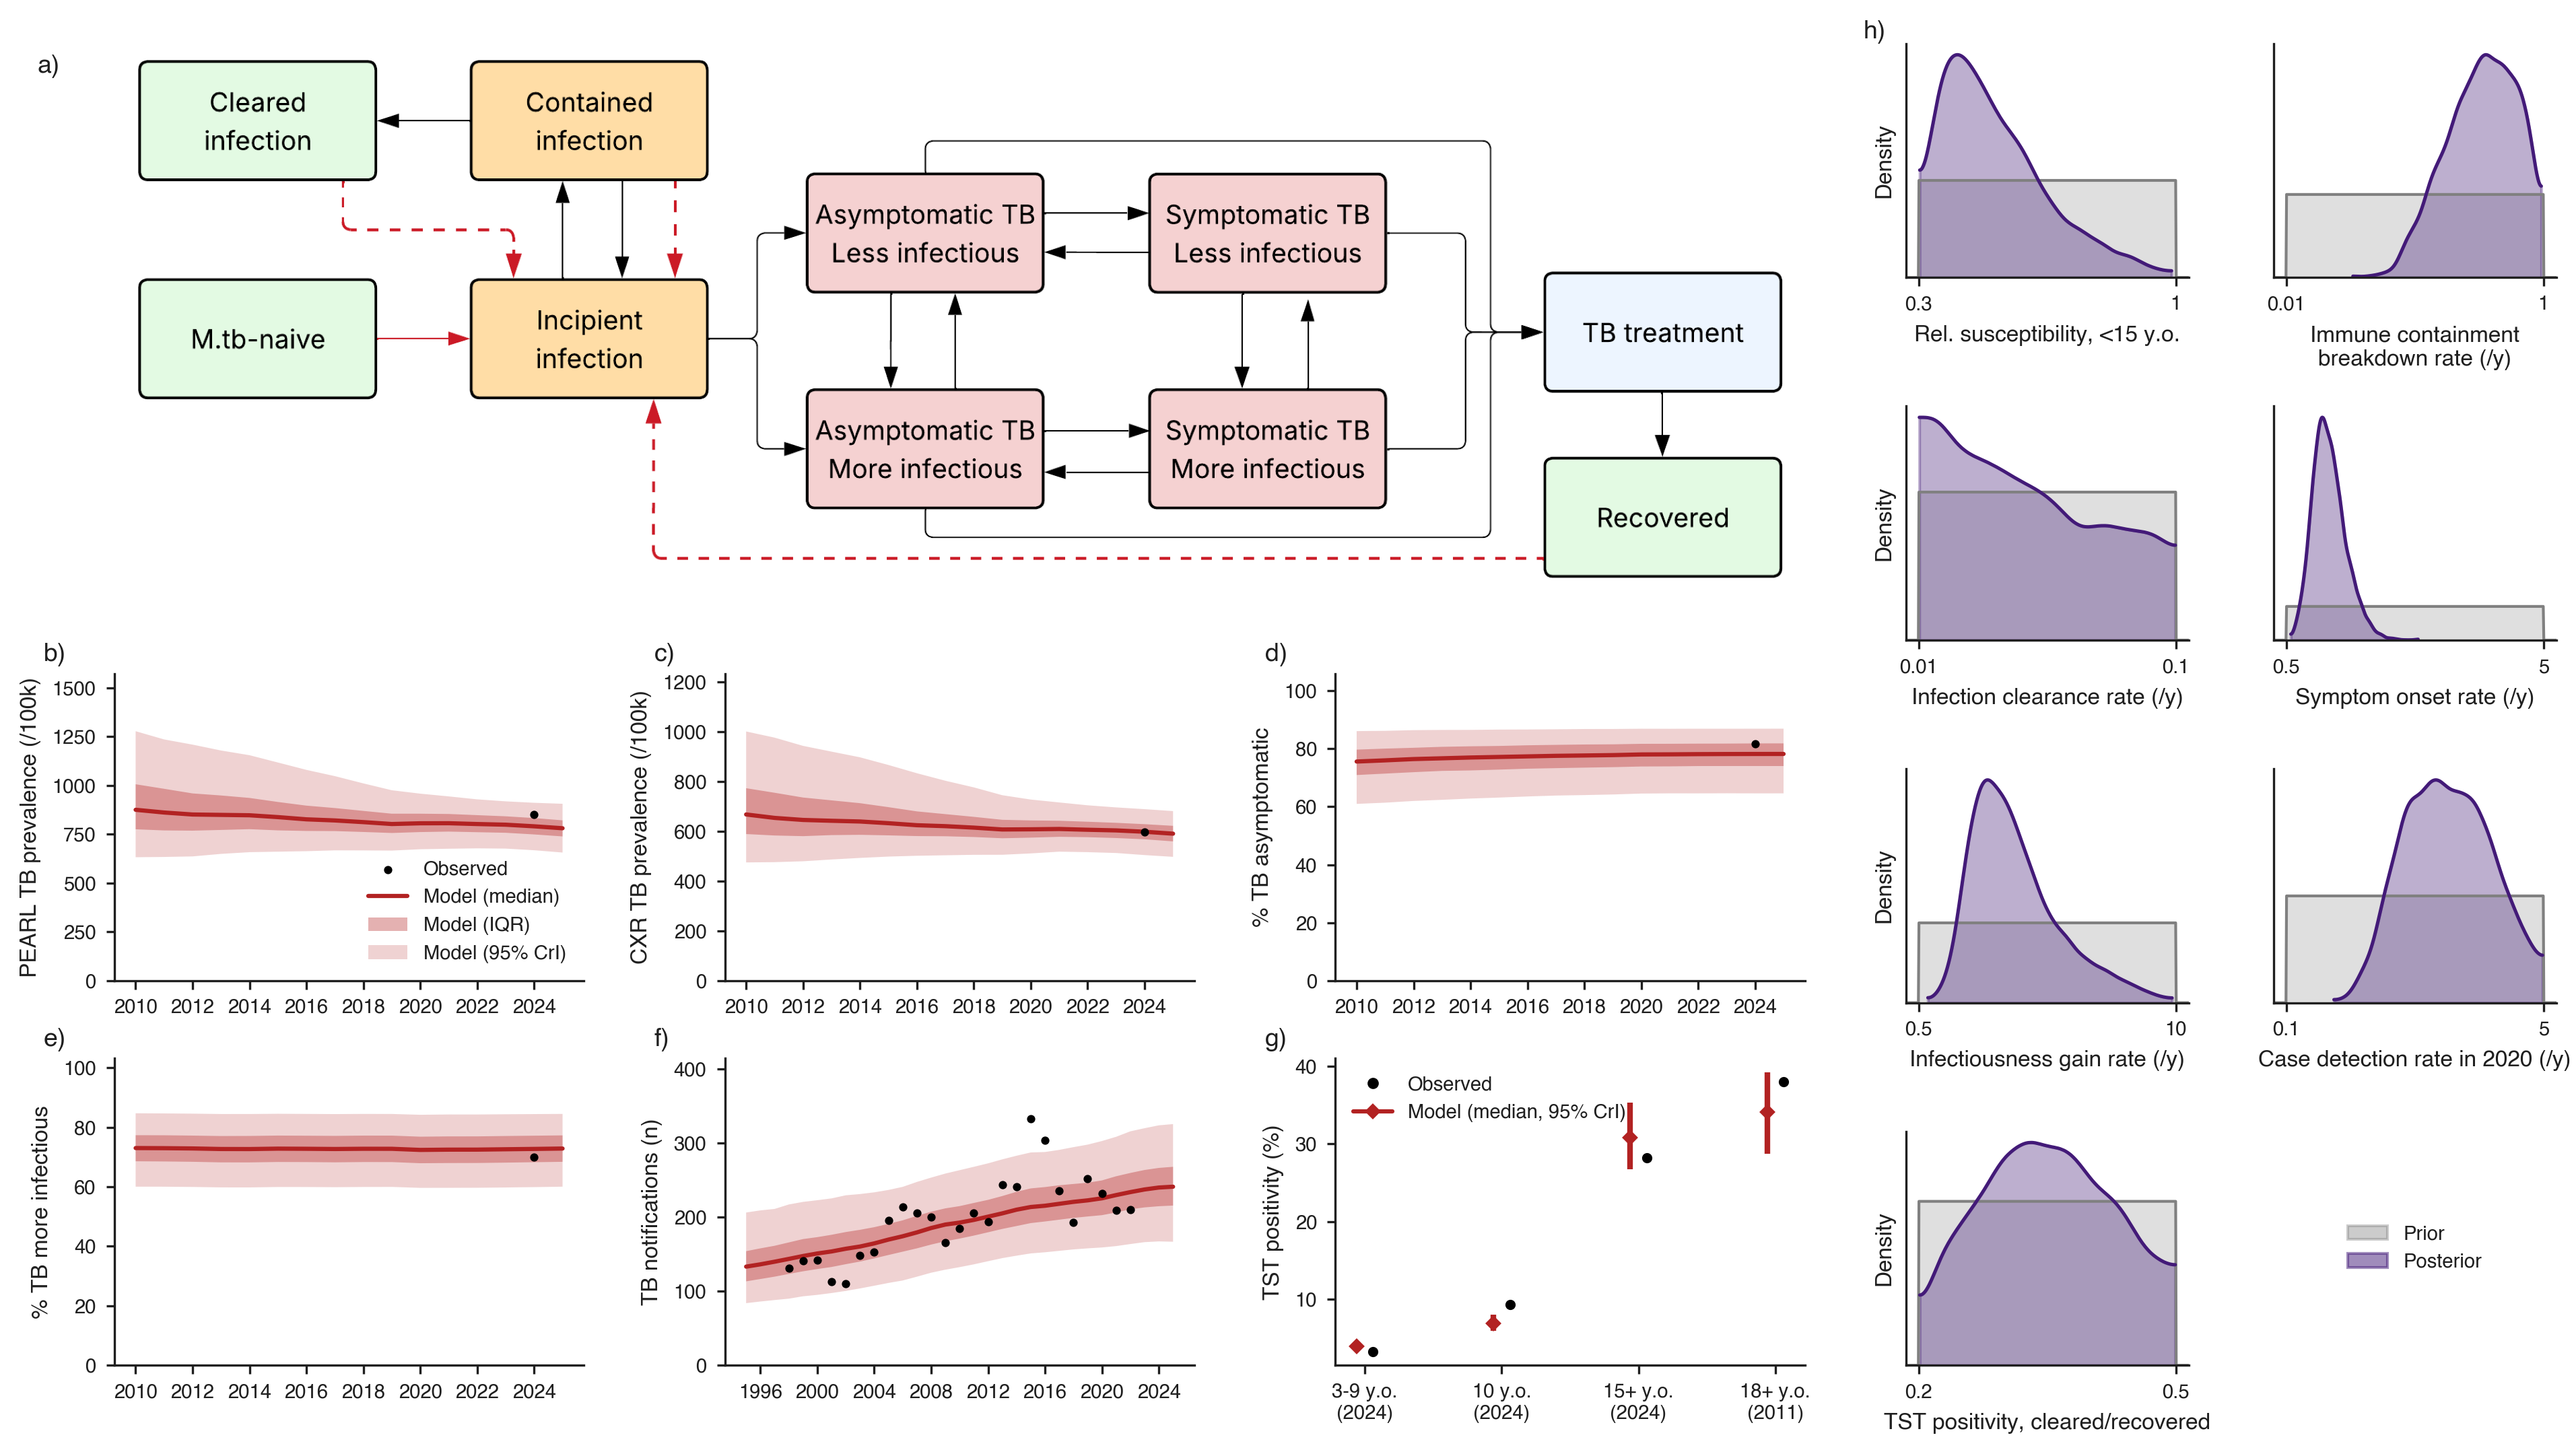

Figure 1 saved


In [23]:
reload(pl)

# Generate Figure 1 (model diagram, calibration panels, prior vs posterior panels)
model_pdf = REPO_ROOT_PATH / "notebooks" / "manuscript_figs" / "tb_model.pdf"
fig1 = pl.make_figure_1_calibration_from_task(
    base_task_path,
    model_pdf_path=model_pdf,
    include_model_panel=True,
    posterior_params=posterior_list,
    posterior_kde_smoothing=2.,   # smoother; try 0.5 for more detail
    posterior_col_width=1.4,
    posterior_gap=0.5,
    posterior_wspace=0.3,
    posterior_hspace=0.55,
    posterior_colour="#431A78",

)
plt.savefig(OUTPUT_DIR / "figure_1_calibration.png", dpi=300, bbox_inches='tight')
plt.savefig(OUTPUT_DIR / "figure_1_calibration.pdf", bbox_inches='tight')
plt.show()

print("Figure 1 saved")

## Figure 2: Projected trajectories

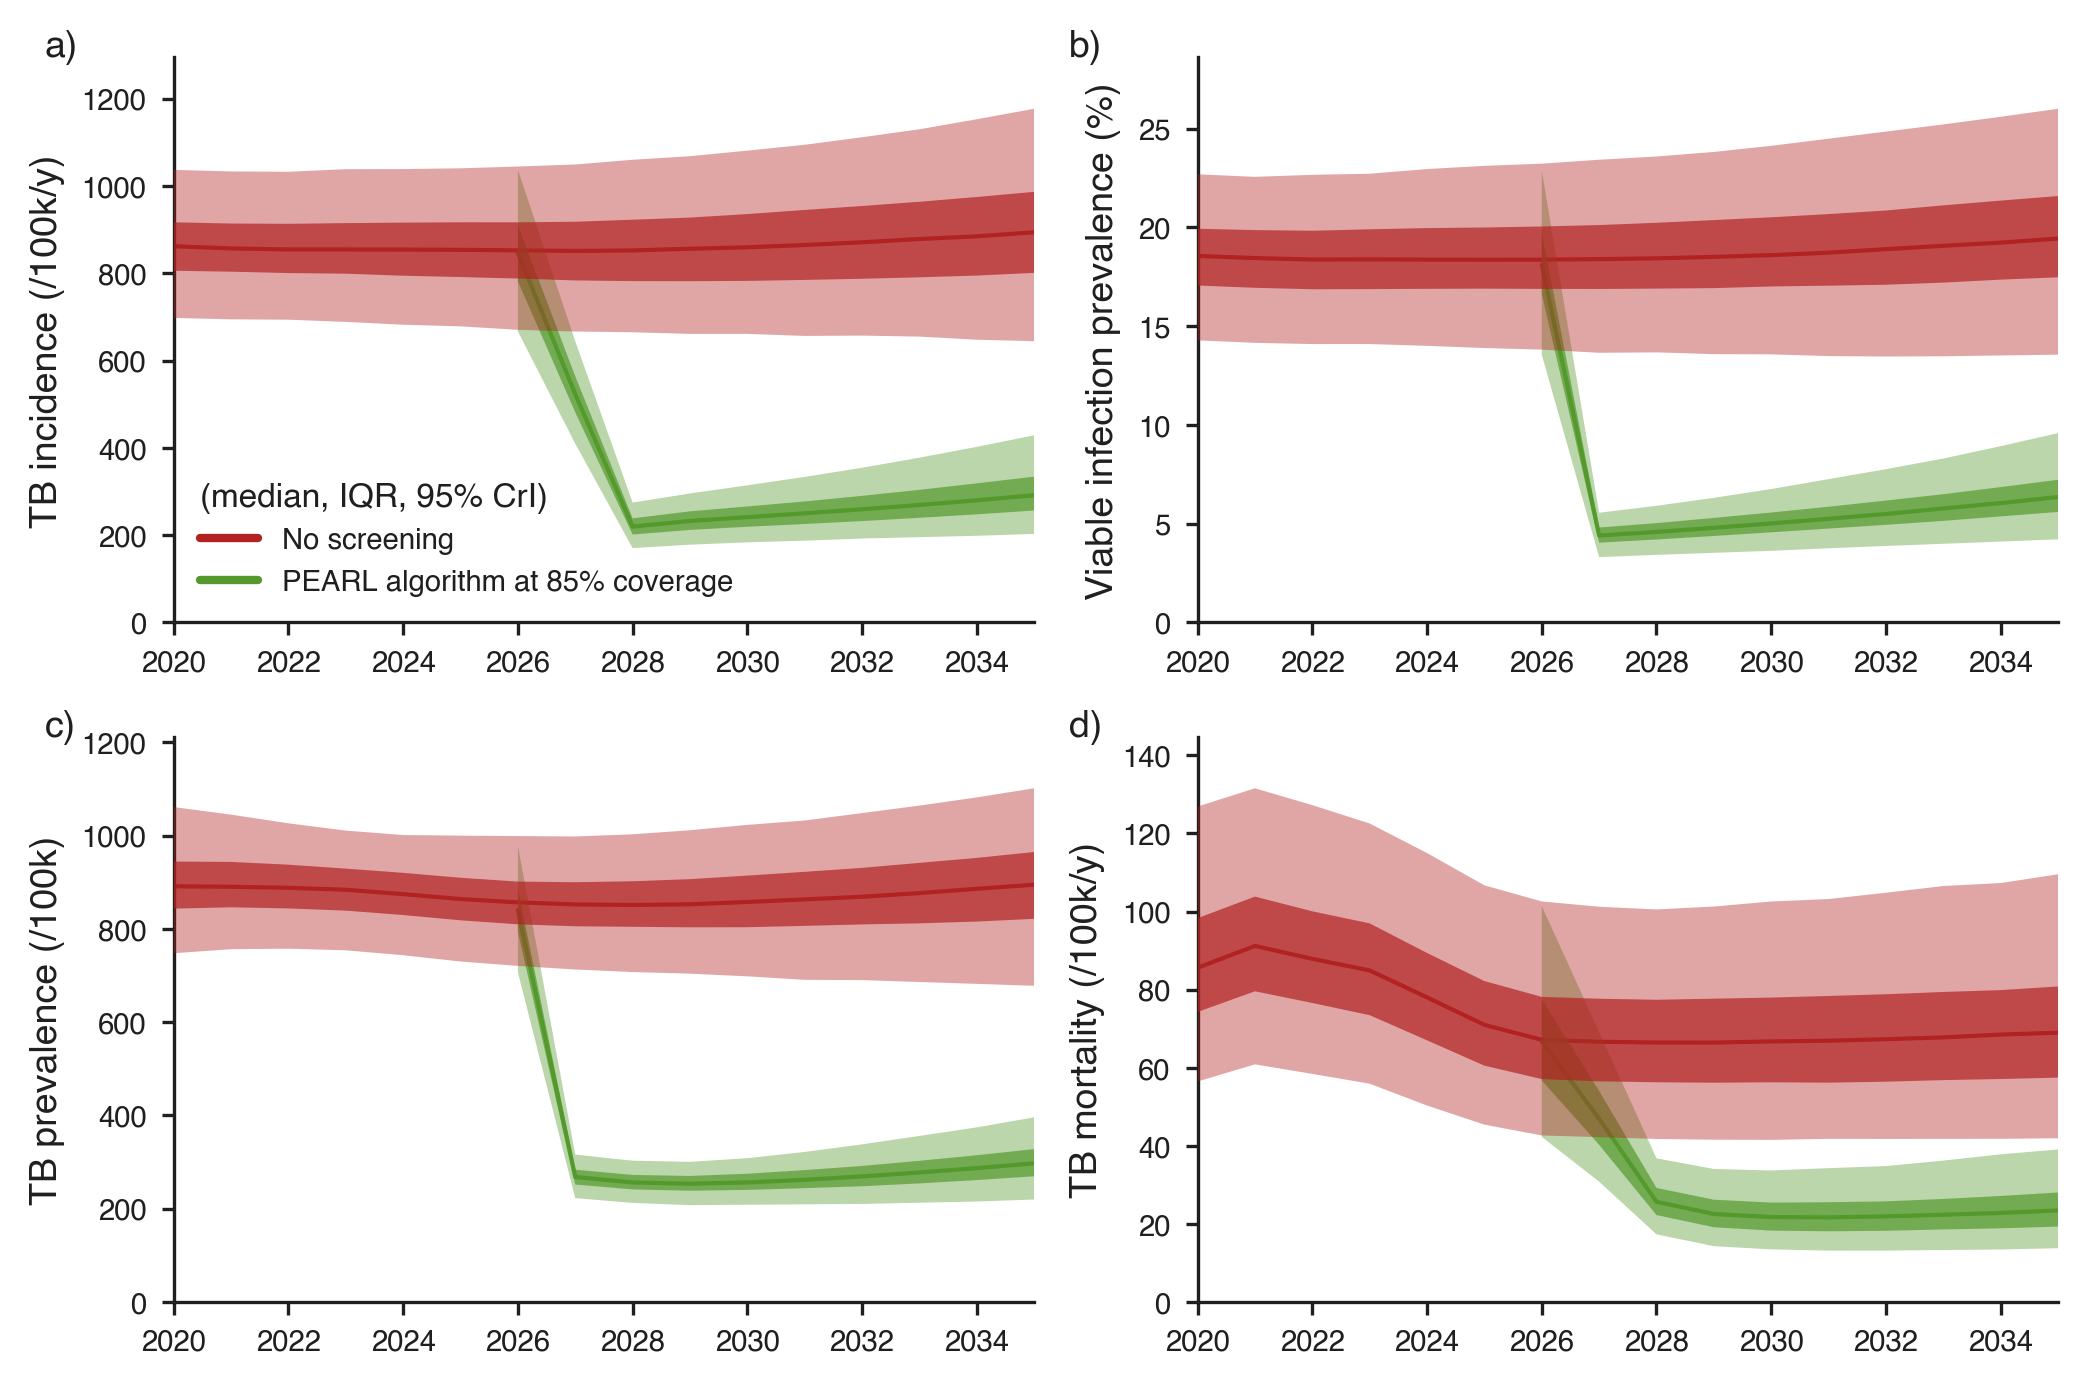

Figure 2 saved


In [9]:
reload(pl)
# Generate Figure 2
fig = pl.make_figure_2_trajectories_from_task(
    base_task_path,
    trajectory_outputs=TRAJECTORY_OUTPUTS,
    scenarios=("baseline", "scenario_3"),
    xlim=(2020, 2035),
    unc_sc_colours=("#B22222", "#54992c"),
    sc_names=SC_NAMES_CUSTOM,
)
plt.savefig(OUTPUT_DIR / "figure_2_trajectories.png", dpi=300, bbox_inches='tight')
plt.savefig(OUTPUT_DIR / "figure_2_trajectories.pdf", bbox_inches='tight')
plt.show()

print("Figure 2 saved")

## Figure 3: Sensitivity to hard-to-reach population

In [10]:
# Part A: Proportion of TB incidence from hard-to-reach (2026 vs 2028)
scenario = "scenario_3"
years_to_plot = [2026, 2028]
target_rel_sus_values = [1.0, 1.5, 2.0, 3.0]
target_reg = 1.0
output_name = "prop_tb_incidenceXreach_unreachable"

rows = []
for _, row in completed_df.iterrows():
    task_path = Path(row["task_path"])
    task_cfg = row.get("task_config", {})
    
    if not isinstance(task_cfg, dict):
        continue
    
    rel_sus = pd.to_numeric(task_cfg.get("rel_sus_unreachable"), errors="coerce")
    reg = pd.to_numeric(task_cfg.get("clinical_regression_rate"), errors="coerce")
    
    if pd.isna(rel_sus) or pd.isna(reg):
        continue
    if not np.isclose(reg, target_reg):
        continue
    if rel_sus not in target_rel_sus_values:
        continue
    
    unc_file = task_path / f"uncertainty_df_{scenario}.parquet"
    if not unc_file.exists():
        continue
    
    unc_df = pd.read_parquet(unc_file)
    if output_name not in unc_df.columns:
        continue
    
    for yr in years_to_plot:
        if yr not in unc_df.index:
            continue
        
        q = unc_df[output_name].loc[yr]
        median = q["0.5"] if "0.5" in q.index else q[0.5]
        low = q["0.025"] if "0.025" in q.index else q[0.025]
        high = q["0.975"] if "0.975" in q.index else q[0.975]
        
        rows.append({
            "rel_sus_unreachable": float(rel_sus),
            "year": int(yr),
            "median_pct": 100.0 * float(median),
            "low_pct": 100.0 * float(low),
            "high_pct": 100.0 * float(high),
        })

plot_df_fig3a = pd.DataFrame(rows)
plot_df_fig3a = plot_df_fig3a.groupby(["rel_sus_unreachable", "year"], as_index=False)[["median_pct", "low_pct", "high_pct"]].median()
plot_df_fig3a = plot_df_fig3a.sort_values(["rel_sus_unreachable", "year"]).reset_index(drop=True)

print("Figure 3a data prepared")

Figure 3a data prepared


In [11]:
# Part B: Impact sensitivity across rel_sus and clinical regression rates
sc_id_list = [3]  # scenario_3

for sc_id in sc_id_list:
    scenario_data = []
    
    for _, row in completed_df.iterrows():
        task_name = row["task"]
        task_path = Path(row["task_path"])
        task_cfg = row.get("task_config", {})
        
        diff_file = task_path / f"diff_quantiles_df_ref_baseline_scenario_{sc_id}.parquet"
        if diff_file.exists():
            df_diff = pd.read_parquet(diff_file)
            scenario_data.append({
                "task": task_name,
                "rel_sus_unreachable": task_cfg.get("rel_sus_unreachable") if isinstance(task_cfg, dict) else None,
                "clinical_regression_rate": task_cfg.get("clinical_regression_rate") if isinstance(task_cfg, dict) else None,
                "TB_averted_relative": df_diff.loc[0.5, "TB_averted_relative"],
                "TB_averted_relative_low": df_diff.loc[0.025, "TB_averted_relative"],
                "TB_averted_relative_high": df_diff.loc[0.975, "TB_averted_relative"],
            })
    
    scenario_df = pd.DataFrame(scenario_data)
    
    for col in [
        "rel_sus_unreachable",
        "clinical_regression_rate",
        "TB_averted_relative",
        "TB_averted_relative_low",
        "TB_averted_relative_high",
    ]:
        scenario_df[col] = pd.to_numeric(scenario_df[col], errors="coerce")
    
    scenario_df = scenario_df.dropna(
        subset=[
            "rel_sus_unreachable",
            "clinical_regression_rate",
            "TB_averted_relative",
            "TB_averted_relative_low",
            "TB_averted_relative_high",
        ]
    ).copy()
    
    scenario_df = scenario_df.sort_values(
        ["clinical_regression_rate", "rel_sus_unreachable"]
    ).reset_index(drop=True)
    scenario_df["x"] = range(len(scenario_df))
    
    plot_df_fig3b = scenario_df

print("Figure 3b data prepared")

Figure 3b data prepared


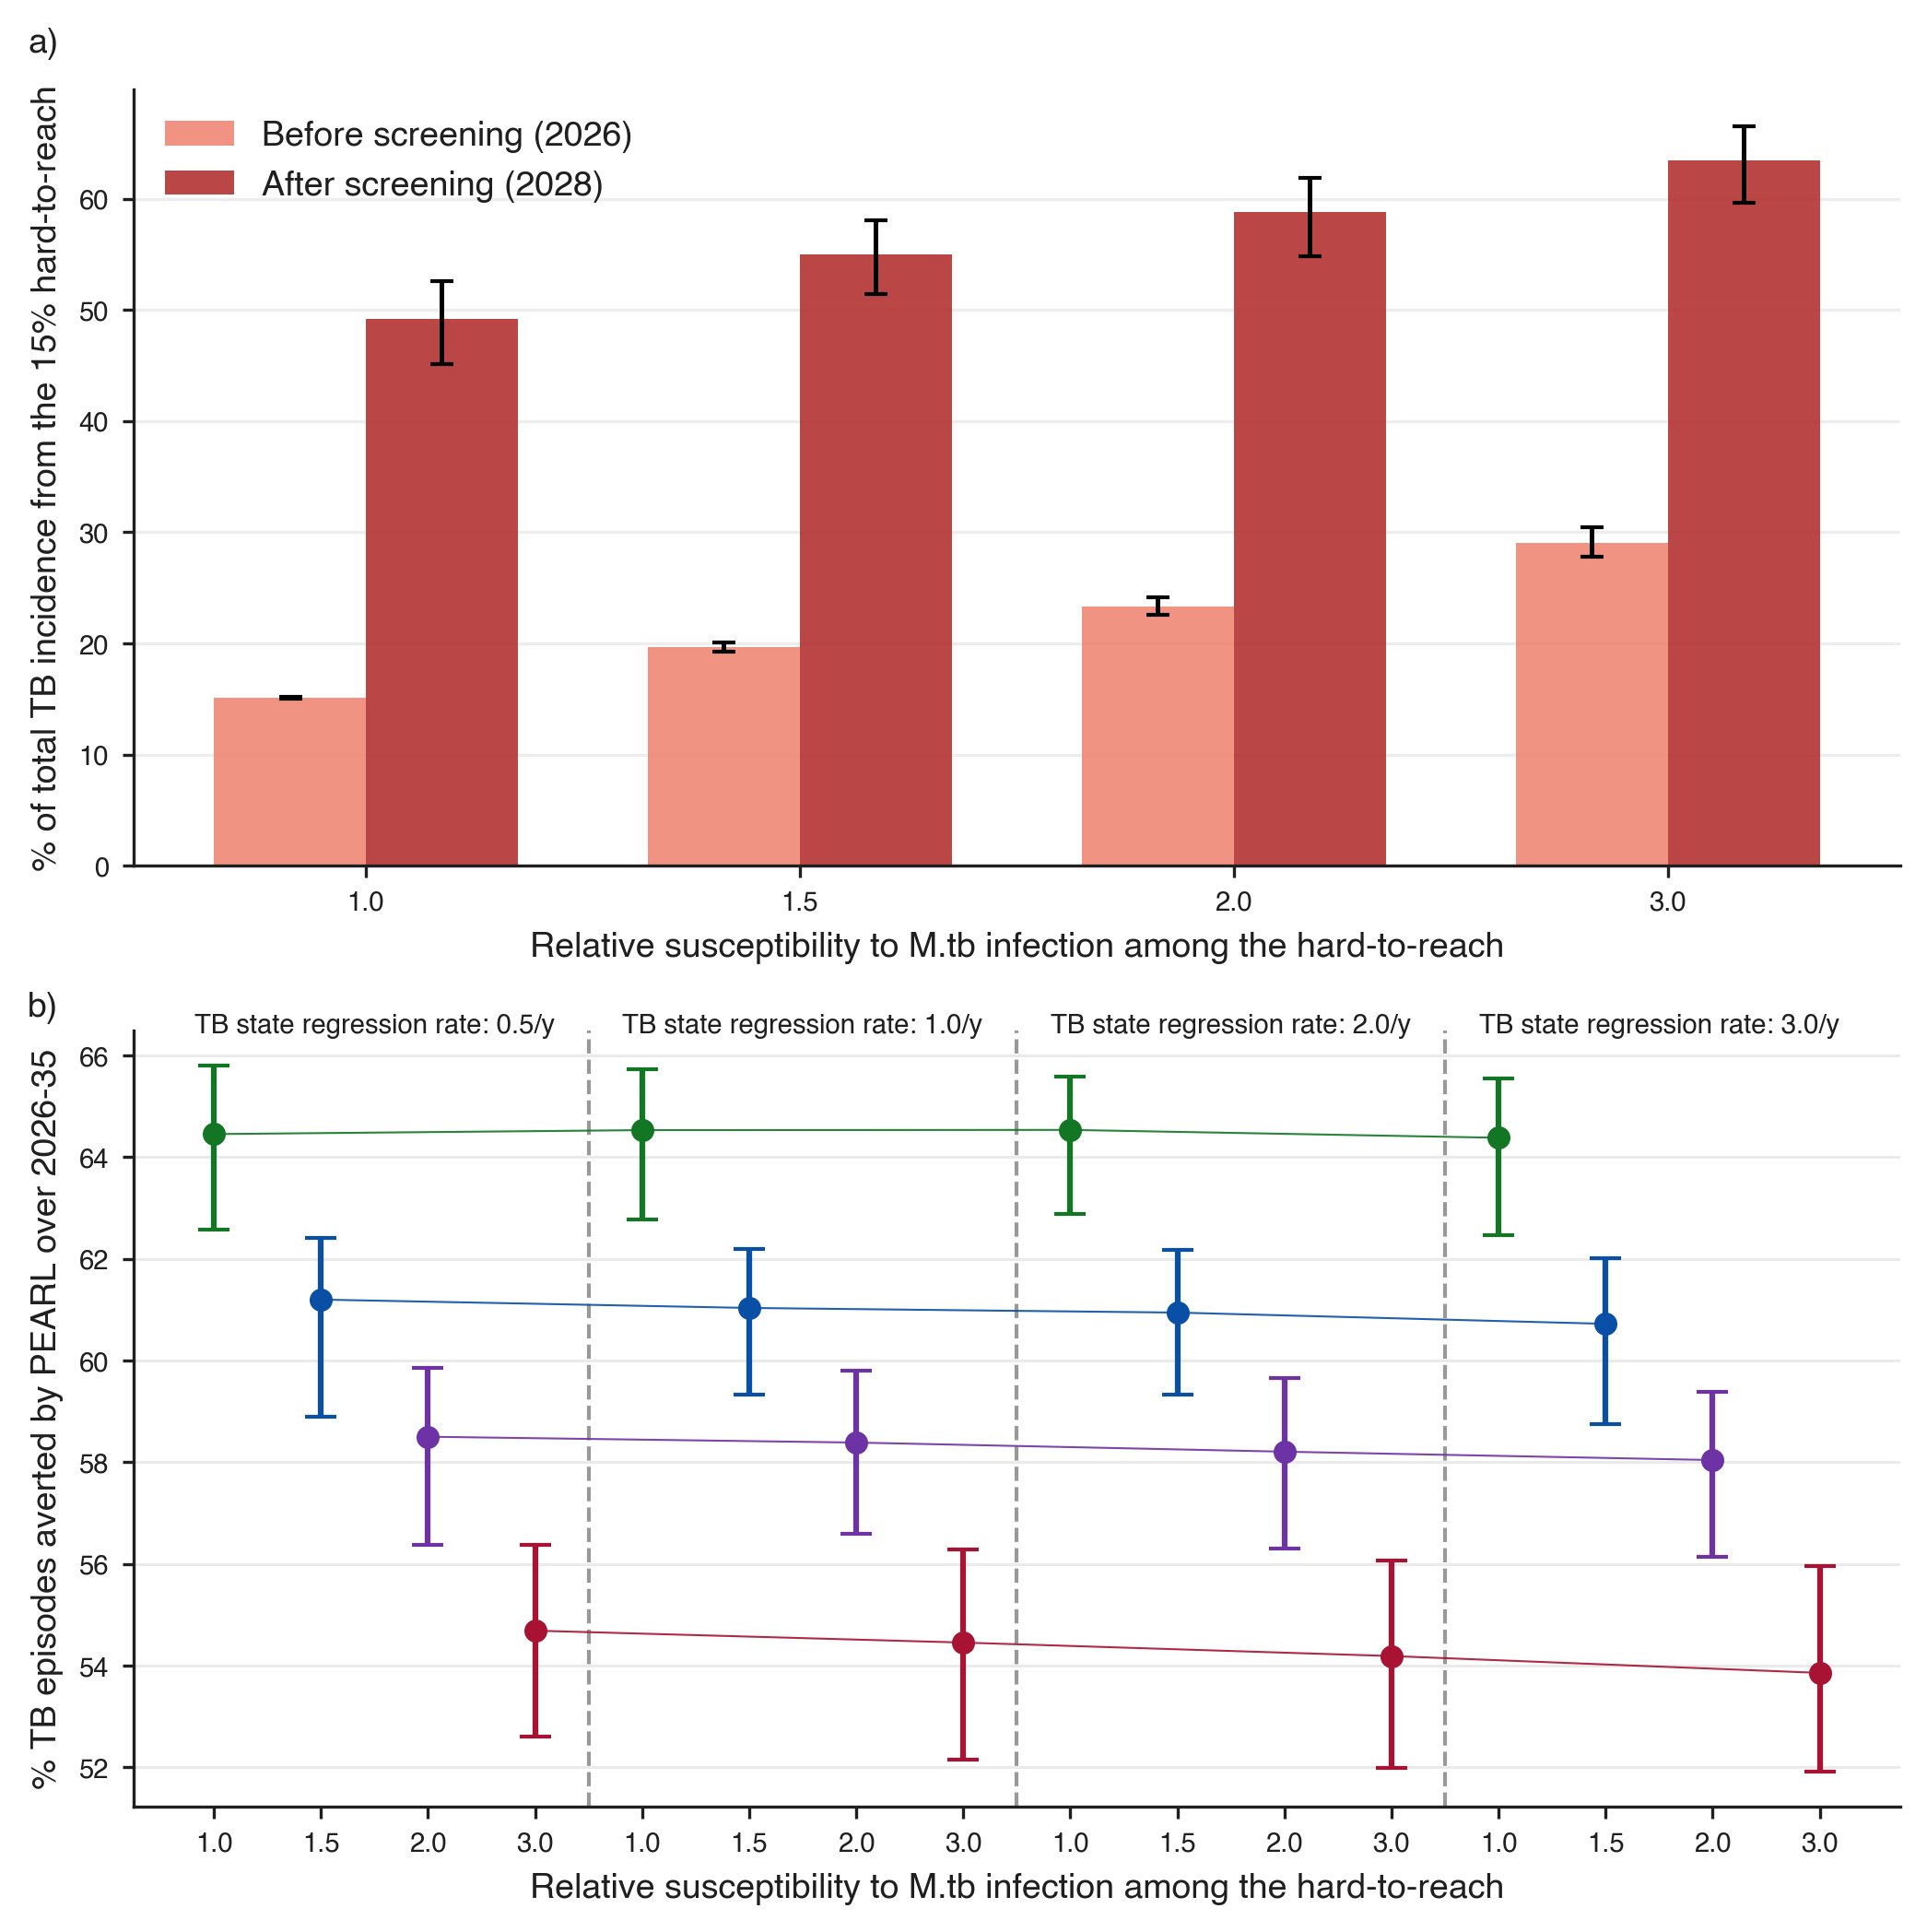

Figure 3 (combined panels a and b) saved


In [12]:
# Generate Figure 3: Combined sensitivity analysis (bar plot and line plot)
year_colors = {2026: "#EF8775", 2028: "#b43232"}
rel_sus_palette = {
    1.0: "#127624",
    1.5: "#094fa5",
    2.0: "#6d32a4",
    3.0: "#a81334",
}
default_rel_sus_color = "#7f7f7f"

fig, axes = plt.subplots(2, 1, figsize=(7, 7))

# Panel A: Bar plot (2026 vs 2028)
ax = axes[0]
x = np.arange(len(target_rel_sus_values), dtype=float)
bar_width = 0.35

year_offsets = {
    years_to_plot[0]: -bar_width / 2.0,
    years_to_plot[1]: bar_width / 2.0,
}

leg_label = {2026: "Before screening (2026)", 2028: "After screening (2028)"}

for yr in years_to_plot:
    sub = (
        plot_df_fig3a.loc[plot_df_fig3a["year"] == yr]
        .set_index("rel_sus_unreachable")
        .reindex(target_rel_sus_values)
        .reset_index()
    )
    
    y = sub["median_pct"].to_numpy()
    y_low = sub["low_pct"].to_numpy()
    y_high = sub["high_pct"].to_numpy()
    
    x_pos = x + year_offsets[yr]
    
    ax.bar(
        x_pos,
        y,
        width=bar_width,
        color=year_colors.get(yr, "#333333"),
        alpha=0.9,
        label=leg_label[yr],
        zorder=2,
    )
    ax.errorbar(
        x_pos,
        y,
        yerr=[y - y_low, y_high - y],
        fmt="none",
        ecolor="black",
        elinewidth=1.2,
        capsize=3,
        zorder=3,
    )

ax.set_xticks(x)
ax.set_xticklabels([f"{v:.1f}" for v in target_rel_sus_values], fontsize=7)
ax.set_xlabel("Relative susceptibility to M.tb infection among the hard-to-reach", fontsize=9)
ax.set_ylabel("% of total TB incidence from the 15% hard-to-reach", fontsize=9)
ax.grid(axis="y", alpha=0.35, zorder=1)
ax.legend(frameon=False, fontsize=9)
ax.text(-0.06, 1.08, "a)", transform=ax.transAxes, fontsize=9, fontweight='bold', va='top')

# Panel B: Line plot
ax = axes[1]
rel_sus_values = sorted(plot_df_fig3b["rel_sus_unreachable"].unique())
for rel_sus in rel_sus_values:
    sub = plot_df_fig3b.loc[
        plot_df_fig3b["rel_sus_unreachable"] == rel_sus
    ].sort_values("x")
    
    xs = sub["x"].to_numpy()
    y = 100.0 * sub["TB_averted_relative"].to_numpy()
    y_low = 100.0 * sub["TB_averted_relative_low"].to_numpy()
    y_high = 100.0 * sub["TB_averted_relative_high"].to_numpy()
    
    series_color = rel_sus_palette.get(float(rel_sus), default_rel_sus_color)
    
    ax.errorbar(
        xs,
        y,
        yerr=[y - y_low, y_high - y],
        fmt="o",
        color=series_color,
        ecolor=series_color,
        markersize=5,
        elinewidth=1.5,
        capsize=4,
        zorder=3,
        label=f"rel_sus = {rel_sus:.1f}",
    )
    if len(xs) > 1:
        ax.plot(xs, y, color=series_color, linewidth=0.5, alpha=0.9, zorder=2)

# Vertical separators after datapoints 4, 8, and 12
for sep in [3.5, 7.5, 11.5]:
    if sep < len(plot_df_fig3b) - 0.5:
        ax.axvline(sep, color="0.5", linestyle="--", linewidth=1.0, alpha=0.8, zorder=1)

x_all = plot_df_fig3b["x"].to_numpy()
ax.set_xticks(x_all)
ax.set_xticklabels([f"{v:.1f}" for v in plot_df_fig3b["rel_sus_unreachable"]], rotation=0, fontsize=7)
ax.set_xlabel("Relative susceptibility to M.tb infection among the hard-to-reach", fontsize=9)
ax.set_ylabel("% TB episodes averted by PEARL over 2026-35", fontsize=9)
ax.grid(axis="y", linestyle="-", linewidth=0.7, alpha=0.4)
# ax.legend(frameon=False, fontsize=7, loc='upper left')
ax.text(-0.06, 1.05, "b)", transform=ax.transAxes, fontsize=9, fontweight='bold', va='top')

# Group labels for clinical regression rate
group_size = 4
reg_values = plot_df_fig3b["clinical_regression_rate"].drop_duplicates().tolist()
for i, reg in enumerate(reg_values):
    start = i * group_size
    end = min(start + group_size - 1, len(plot_df_fig3b) - 1)
    if start <= end:
        center = (start + end) / 2.0
        ax.text(
            center,
            0.99,
            f"TB state regression rate: {reg:.1f}/y",
            ha="center",
            va="bottom",
            transform=ax.get_xaxis_transform(),
            fontsize=7,
            color=text_color,
        )

fig.tight_layout()
plt.savefig(OUTPUT_DIR / "figure_3_sensitivity_analysis.png", dpi=300, bbox_inches='tight')
plt.savefig(OUTPUT_DIR / "figure_3_sensitivity_analysis.pdf", bbox_inches='tight')
plt.show()

print("Figure 3 (combined panels a and b) saved")

## Figure 4: Algorithm and coverage comparison

In [13]:
# Scenario ordering for Figure 4
scenarios_to_compare = ["scenario_1", "scenario_2","scenario_3", "scenario_6", "scenario_7", "scenario_8", "scenario_16", "scenario_17", "scenario_18"]
print("Figure 4 scenario order configured")

Figure 4 scenario order configured


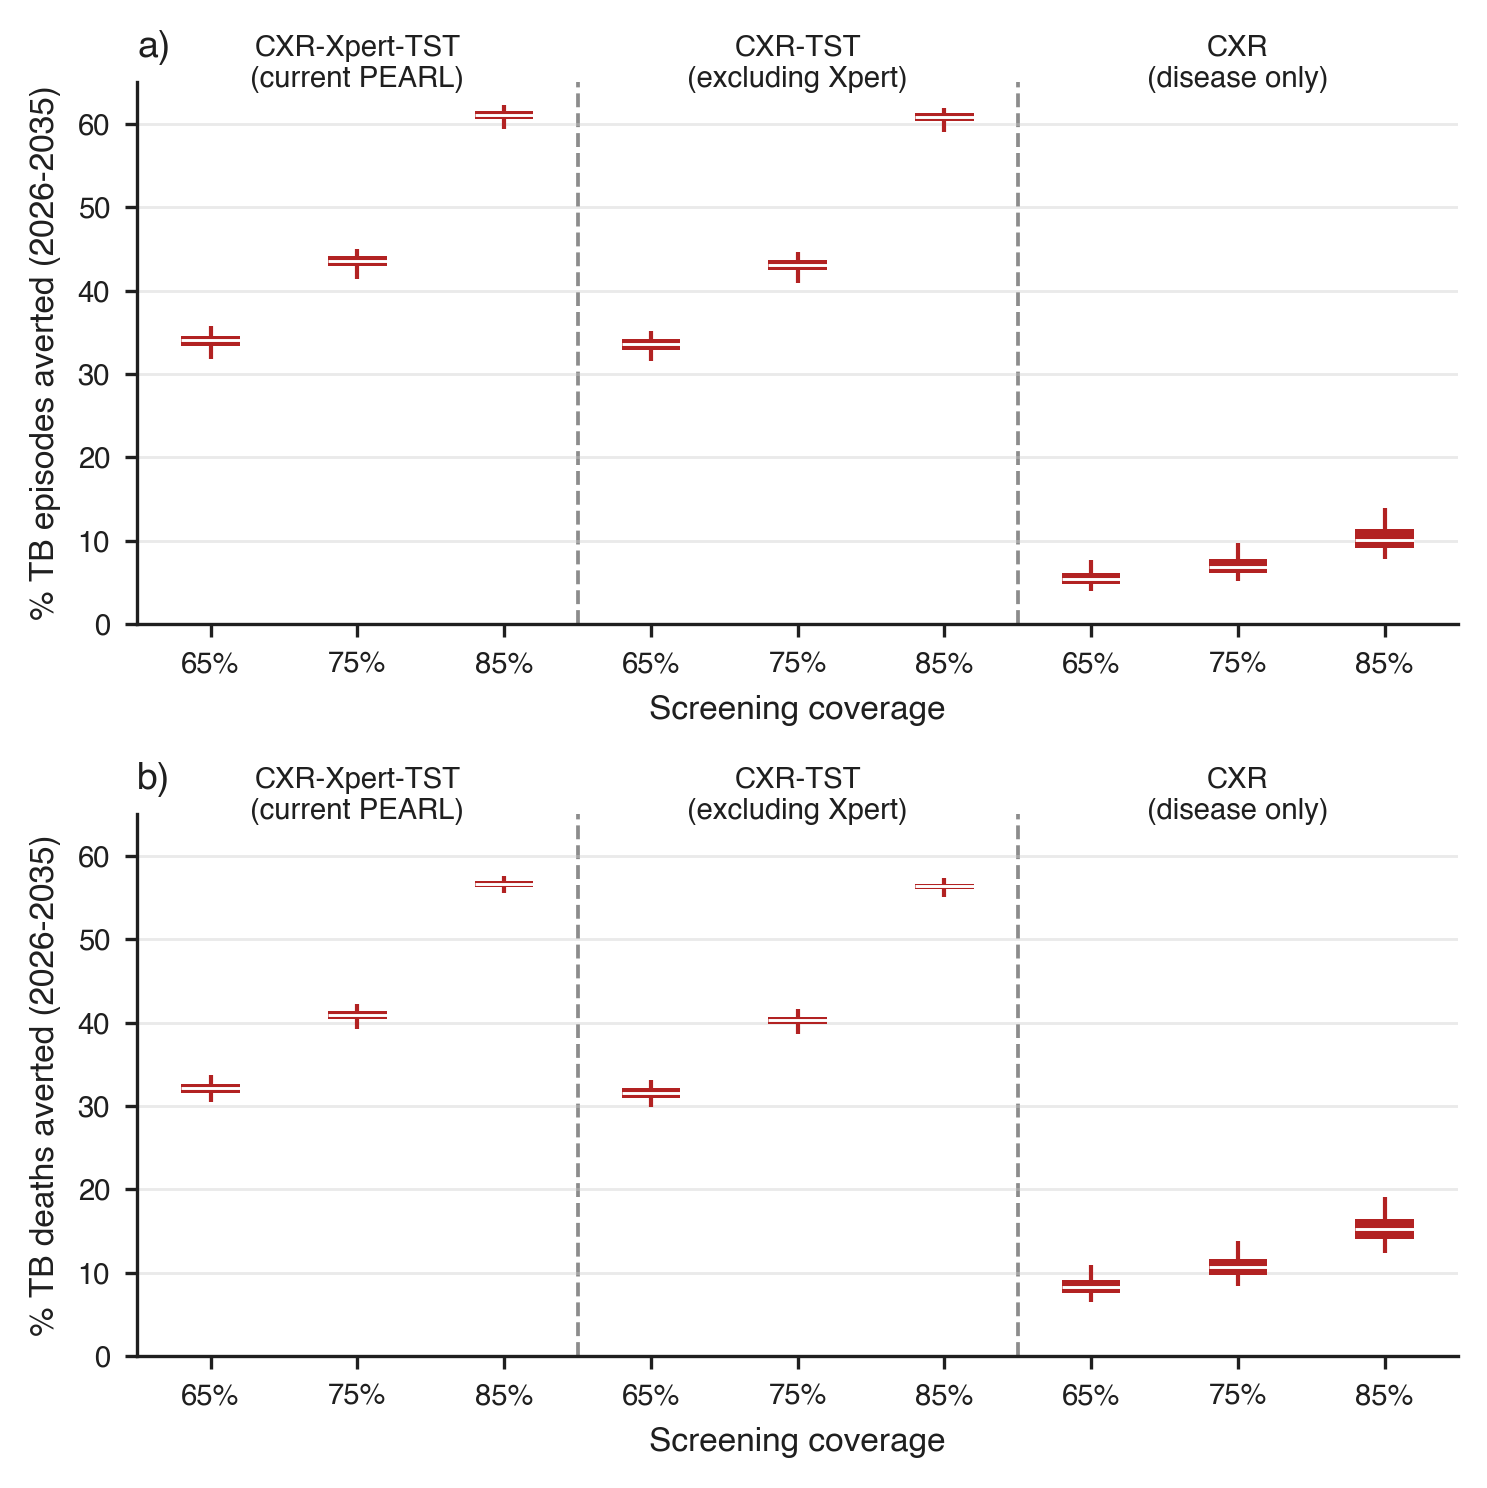

Figure 4 saved


In [14]:
# Generate Figure 4: Algorithm and coverage comparison
reload(pl)

fig = pl.make_figure_4_algorithms_coverage_from_task(
    base_task_path,
    scenarios_to_compare=scenarios_to_compare,
    colour="#B22222",
)
plt.savefig(OUTPUT_DIR / "figure_4_algorithms_coverage.png", dpi=300, bbox_inches='tight')
plt.savefig(OUTPUT_DIR / "figure_4_algorithms_coverage.pdf", bbox_inches='tight')
plt.show()

print("Figure 4 saved")

## Results text auto-population

In [15]:
# Auto-populate the full Results-section text using estimates from the selected output folder.
# Assumes earlier cells have defined: base_dir, completed_df, SA_BASE_DIR (for sensitivity analyses).

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Markdown, display


def _load_unc(task_path, scenario):
    p = task_path / f"uncertainty_df_{scenario}.parquet"
    if not p.exists():
        raise FileNotFoundError(f"Missing uncertainty file: {p}")
    return pd.read_parquet(p)


def _load_diff(task_path, scenario):
    p = task_path / f"diff_quantiles_df_ref_baseline_{scenario}.parquet"
    if not p.exists():
        raise FileNotFoundError(f"Missing diff file: {p}")
    return pd.read_parquet(p)


def _q(unc_df, output, year, quantile):
    q_key = str(quantile)
    return float(unc_df.loc[float(year), (output, q_key)])


def _cri(unc_df, output, year, scale=1.0, dec=0):
    med = scale * _q(unc_df, output, year, 0.5)
    low = scale * _q(unc_df, output, year, 0.025)
    high = scale * _q(unc_df, output, year, 0.975)
    f = f"{{:.{dec}f}}"
    return f.format(med), f.format(low), f.format(high)


def _find_task_row(df, rel_sus=None, reg=None):
    x = df.copy()
    x["rel_sus_unreachable"] = pd.to_numeric(
        x["task_config"].apply(lambda d: d.get("rel_sus_unreachable") if isinstance(d, dict) else np.nan),
        errors="coerce",
    )
    x["clinical_regression_rate"] = pd.to_numeric(
        x["task_config"].apply(lambda d: d.get("clinical_regression_rate") if isinstance(d, dict) else np.nan),
        errors="coerce",
    )

    if rel_sus is not None:
        x = x[np.isclose(x["rel_sus_unreachable"], rel_sus)]
    if reg is not None:
        x = x[np.isclose(x["clinical_regression_rate"], reg)]

    if x.empty:
        raise ValueError(f"No task found for rel_sus={rel_sus}, reg={reg}")

    return x.sort_values("task").iloc[0]


def _pct_averted(diff_df, col):
    return (
        100.0 * float(diff_df.loc[0.5, col]),
        100.0 * float(diff_df.loc[0.025, col]),
        100.0 * float(diff_df.loc[0.975, col]),
    )


def _load_sa_unc(sa_task_path, scenario):
    """Load uncertainty data from sensitivity analysis folder."""
    p = sa_task_path / f"uncertainty_df_{scenario}.parquet"
    if not p.exists():
        raise FileNotFoundError(f"Missing SA uncertainty file: {p}")
    return pd.read_parquet(p)


def _load_sa_diff(sa_task_path, scenario):
    """Load diff data from sensitivity analysis folder."""
    p = sa_task_path / f"diff_quantiles_df_ref_baseline_{scenario}.parquet"
    if not p.exists():
        raise FileNotFoundError(f"Missing SA diff file: {p}")
    return pd.read_parquet(p)


# Choose base-case task for manuscript text.
# Current convention here: rel_sus_unreachable=1.5 and clinical_regression_rate=1.0.
base_task = _find_task_row(completed_df, rel_sus=1.5, reg=1.0)
base_task_name = base_task["task"]
base_task_path = Path(base_task["task_path"])

unc_baseline = _load_unc(base_task_path, "baseline")
unc_sc3 = _load_unc(base_task_path, "scenario_3")
diff_sc3 = _load_diff(base_task_path, "scenario_3")

# Core burden estimates at the beginning of 2026 (before screening)
prev_2026_med, prev_2026_low, prev_2026_high = _cri(unc_baseline, "tb_prevalence_per100k", 2026, scale=1.0, dec=0)
inc_2026_med, inc_2026_low, inc_2026_high = _cri(unc_baseline, "tb_incidence_per100k", 2026, scale=1.0, dec=0)
vtbi_2026_med, vtbi_2026_low, vtbi_2026_high = _cri(unc_baseline, "viable_tbi_prevalence_perc", 2026, scale=1.0, dec=0)

# 2028 vs 2026 reductions under PEARL-like screening (scenario_3)
prev_2026_sc3 = _q(unc_sc3, "tb_prevalence_per100k", 2026, 0.5)
prev_2028_sc3 = _q(unc_sc3, "tb_prevalence_per100k", 2028, 0.5)
vtbi_2026_sc3 = _q(unc_sc3, "viable_tbi_prevalence_perc", 2026, 0.5)
vtbi_2028_sc3 = _q(unc_sc3, "viable_tbi_prevalence_perc", 2028, 0.5)

prev_drop_pct = 100.0 * (prev_2026_sc3 - prev_2028_sc3) / prev_2026_sc3
vtbi_drop_pct = 100.0 * (vtbi_2026_sc3 - vtbi_2028_sc3) / vtbi_2026_sc3

# 2028 incidence and mortality under screening
inc_2028_sc3_med, _, _ = _cri(unc_sc3, "tb_incidence_per100k", 2028, scale=1.0, dec=0)
mort_2028_sc3_med, _, _ = _cri(unc_sc3, "tb_mortality_per100k", 2028, scale=1.0, dec=0)

# 2035 incidence with and without screening
inc_2035_sc3_med, _, _ = _cri(unc_sc3, "tb_incidence_per100k", 2035, scale=1.0, dec=0)
inc_2035_base_med, _, _ = _cri(unc_baseline, "tb_incidence_per100k", 2035, scale=1.0, dec=0)

# Cumulative impact during 2026-35 (from diff outputs)
tb_av_med, tb_av_low, tb_av_high = _pct_averted(diff_sc3, "TB_averted_relative")
d_av_med, d_av_low, d_av_high = _pct_averted(diff_sc3, "deaths_averted_relative")

# Sensitivity: impact at rel_sus 1.0 vs 3.0, fixing clinical_regression_rate=1.0
task_rel1 = _find_task_row(completed_df, rel_sus=1.0, reg=1.0)
task_rel3 = _find_task_row(completed_df, rel_sus=3.0, reg=1.0)

diff_rel1 = _load_diff(Path(task_rel1["task_path"]), "scenario_3")
diff_rel3 = _load_diff(Path(task_rel3["task_path"]), "scenario_3")
unc_rel3_sc3 = _load_unc(Path(task_rel3["task_path"]), "scenario_3")

rel1_med, rel1_low, rel1_high = _pct_averted(diff_rel1, "TB_averted_relative")
rel3_med, rel3_low, rel3_high = _pct_averted(diff_rel3, "TB_averted_relative")

# Contribution of hard-to-reach population to TB incidence (figure 3 text)
unreach_before_base = 100.0 * _q(unc_baseline, "prop_tb_incidenceXreach_unreachable", 2026, 0.5)
unreach_after_base = 100.0 * _q(unc_sc3, "prop_tb_incidenceXreach_unreachable", 2028, 0.5)
unreach_before_rel3 = 100.0 * _q(unc_rel3_sc3, "prop_tb_incidenceXreach_unreachable", 2026, 0.5)
unreach_after_rel3 = 100.0 * _q(unc_rel3_sc3, "prop_tb_incidenceXreach_unreachable", 2028, 0.5)

# CrI for unreach (hard-to-reach) contributions
unreach_before_base_low = 100.0 * _q(unc_baseline, "prop_tb_incidenceXreach_unreachable", 2026, 0.025)
unreach_before_base_high = 100.0 * _q(unc_baseline, "prop_tb_incidenceXreach_unreachable", 2026, 0.975)
unreach_after_base_low = 100.0 * _q(unc_sc3, "prop_tb_incidenceXreach_unreachable", 2028, 0.025)
unreach_after_base_high = 100.0 * _q(unc_sc3, "prop_tb_incidenceXreach_unreachable", 2028, 0.975)

unreach_before_rel3_low = 100.0 * _q(unc_rel3_sc3, "prop_tb_incidenceXreach_unreachable", 2026, 0.025)
unreach_before_rel3_high = 100.0 * _q(unc_rel3_sc3, "prop_tb_incidenceXreach_unreachable", 2026, 0.975)
unreach_after_rel3_low = 100.0 * _q(unc_rel3_sc3, "prop_tb_incidenceXreach_unreachable", 2028, 0.025)
unreach_after_rel3_high = 100.0 * _q(unc_rel3_sc3, "prop_tb_incidenceXreach_unreachable", 2028, 0.975)

# Algorithm and coverage comparisons (same base-case task)
diff_sc1 = _load_diff(base_task_path, "scenario_1")   # PEARL | 65%
diff_sc3 = _load_diff(base_task_path, "scenario_3")   # PEARL | 85%
diff_sc6 = _load_diff(base_task_path, "scenario_6")   # CXR-TST | 65%
diff_sc8 = _load_diff(base_task_path, "scenario_8")   # CXR-TST | 85%
diff_sc18 = _load_diff(base_task_path, "scenario_18") # Disease screening only | 85%

pearl85_med, _, _ = _pct_averted(diff_sc3, "TB_averted_relative")
cxrtst85_med, _, _ = _pct_averted(diff_sc8, "TB_averted_relative")
abs_diff_85 = abs(pearl85_med - cxrtst85_med)

disease85_med, _, _ = _pct_averted(diff_sc18, "TB_averted_relative")
pearl65_med, _, _ = _pct_averted(diff_sc1, "TB_averted_relative")
cxrtst65_med, _, _ = _pct_averted(diff_sc6, "TB_averted_relative")

# Load sensitivity analysis data (from separate folder)
sa_results = {}
sa_base_dir = Path(SA_BASE_DIR) if 'SA_BASE_DIR' in globals() else None

if sa_base_dir and sa_base_dir.exists():
    # SA task map: task_id -> (sa_name, description)
    sa_map = {
        1: ("tpt_60", "TPT completion 60%"),
        2: ("subclinical_50", "Subclinical prevalence 50%"),
        3: ("homogeneous_mixing", "Homogeneous mixing"),
    }
    
    for task_id, (sa_name, sa_desc) in sa_map.items():
        sa_task_path = sa_base_dir / f"task_{task_id}"
        if sa_task_path.exists():
            try:
                sa_unc_base = _load_sa_unc(sa_task_path, "baseline")
                sa_unc_sc3 = _load_sa_unc(sa_task_path, "scenario_3")
                sa_diff_sc3 = _load_sa_diff(sa_task_path, "scenario_3")
                
                # Key results for this SA
                sa_tb_av_med, sa_tb_av_low, sa_tb_av_high = _pct_averted(sa_diff_sc3, "TB_averted_relative")
                sa_inc_2035_sc3_med, _, _ = _cri(sa_unc_sc3, "tb_incidence_per100k", 2035, scale=1.0, dec=0)
                sa_inc_2035_base_med, _, _ = _cri(sa_unc_base, "tb_incidence_per100k", 2035, scale=1.0, dec=0)
                
                sa_results[sa_name] = {
                    "desc": sa_desc,
                    "tb_averted_med": sa_tb_av_med,
                    "tb_averted_low": sa_tb_av_low,
                    "tb_averted_high": sa_tb_av_high,
                    "inc_2035_sc3": sa_inc_2035_sc3_med,
                    "inc_2035_base": sa_inc_2035_base_med,
                }
            except Exception as e:
                print(f"Warning: Could not load SA data for {sa_name}: {e}")

# Pre-compute SA values to ensure they're always numeric (not strings) for f-string formatting
sa_tpt60_med = sa_results.get('tpt_60', {}).get('tb_averted_med', None)
sa_tpt60_low = sa_results.get('tpt_60', {}).get('tb_averted_low', None)
sa_tpt60_high = sa_results.get('tpt_60', {}).get('tb_averted_high', None)

# If SA data is missing, use placeholder text that will display "XX"
if sa_tpt60_med is None:
    sa_tpt60_text = "XX"
    sa_tpt60_text_low = "XX"
    sa_tpt60_text_high = "XX"
else:
    sa_tpt60_text = f"{sa_tpt60_med:.0f}"
    sa_tpt60_text_low = f"{sa_tpt60_low:.0f}"
    sa_tpt60_text_high = f"{sa_tpt60_high:.0f}"

results_text = f"""Model calibration and estimated TB burden

The model adequately reproduced the observed TB prevalence, disease-state distributions, historical notifications, and age-specific TST positivity (Figure 1). Model fits remained consistent across all configurations varying the susceptibility of the hard-to-reach population and regression rates across the TB disease spectrum (appendix pp 6-25). The calibration data substantially constrained parameters governing transmission, progression across the TB infection-disease spectrum, loss of immune containment, and passive detection. The infection-clearance rate was also informed by the data, although less strongly than these other parameters (appendix Figure S1).  Unless otherwise stated, results presented below correspond to the base-case configuration, which assumed a TB-spectrum regression rate of 1 per year and a 50% higher susceptibility to M.tb infection among hard-to-reach than screening-reachable individuals.

At the beginning of 2026, before screening, the estimated prevalence of TB across the four disease states was {prev_2026_med} per 100 000 population (95% CrI {prev_2026_low}-{prev_2026_high}), and estimated TB incidence was {inc_2026_med} per 100 000 person-years ({inc_2026_low}-{inc_2026_high}). An estimated {vtbi_2026_med}% (95% CrI {vtbi_2026_low}-{vtbi_2026_high}) of the population had viable M.tb infection. These estimates represented the entire modelled population, including screening-reachable and hard-to-reach individuals of all ages.

Projected impact of PEARL-like screening

Implementation of the PEARL algorithm at 85% population coverage was projected to reduce median TB prevalence by {prev_drop_pct:.0f}% and viable infection prevalence by {vtbi_drop_pct:.0f}% between 2026 and 2028 (Figure 2). TB incidence and mortality also declined, reaching median estimates of {inc_2028_sc3_med} per 100 000 person-years and {mort_2028_sc3_med} per 100 000 person-years, respectively, in 2028.

These reductions were projected to be sustained. In 2035, median TB incidence was projected to be {inc_2035_sc3_med} per 100 000 person-years with PEARL-like screening, compared with {inc_2035_base_med} per 100 000 person-years without active screening. Over 2026-35, PEARL-like screening was projected to avert {tb_av_med:.0f}% (95% CrI {tb_av_low:.0f}-{tb_av_high:.0f}) of TB episodes and {d_av_med:.0f}% ({d_av_low:.0f}-{d_av_high:.0f}) of TB deaths expected without active screening.

Sensitivity to the population missed by screening and disease-spectrum assumptions

Projected screening impact was most sensitive to assumptions about the susceptibility of hard-to-reach individuals (Figure 3). At 85% coverage, PEARL-like screening averted {rel1_med:.0f}% (95% CrI {rel1_low:.0f}-{rel1_high:.0f}) of TB episodes during 2026-35 when hard-to-reach and screening-reachable individuals were assumed to have equal susceptibility to M.tb infection, compared with {rel3_med:.0f}% ({rel3_low:.0f}-{rel3_high:.0f}) when hard-to-reach individuals were assumed to have three times the susceptibility of screening-reachable individuals.

Although only 15% of the population was assumed to be hard-to-reach, this group accounted for {unreach_before_base:.0f}% (95% CrI {unreach_before_base_low:.0f}-{unreach_before_base_high:.0f}) of total TB incidence before PEARL-like screening and {unreach_after_base:.0f}% ({unreach_after_base_low:.0f}-{unreach_after_base_high:.0f}) afterwards in the base case, assuming this population was 50% more susceptible than the screening-reachable population. When assuming three-times greater susceptibility to infection, its contribution rose from {unreach_before_rel3:.0f}% (95% CrI {unreach_before_rel3_low:.0f}-{unreach_before_rel3_high:.0f}) before screening to {unreach_after_rel3:.0f}% ({unreach_after_rel3_low:.0f}-{unreach_after_rel3_high:.0f}) after screening (Figure 3).

As we varied the rates of regression across the TB disease spectrum, recalibration produced corresponding changes in the estimated progression rates along both clinical and infectiousness dimensions (Figure S3). Despite these differences in the overall speed of TB-spectrum dynamics, projected screening impact changed only slightly (Figure 3).

Comparison of screening algorithms and coverage

Among strategies that retained TST and TPT, population coverage had a greater influence on projected impact than the inclusion of Xpert in frontline screening (Figure 4). At equivalent coverage, the PEARL and CXR-TST algorithms produced similar reductions in cumulative TB episodes and deaths. At 85% coverage, the median proportions of TB episodes averted during 2026-35 differed by only {abs_diff_85:.1f} percentage points between these algorithms, indicating that removal of Xpert from frontline screening had only a modest effect on projected population-level impact.

In contrast, removing TST and TPT substantially reduced both the magnitude and durability of the intervention effect. Even at 85% coverage, disease screening alone averted only around {disease85_med:.0f}% of TB episodes during 2026-35, less than the {pearl65_med:.0f}% averted by the PEARL or CXR-TST algorithms at 65% coverage. Similar patterns were observed for cumulative TB deaths (Figure 4). These findings suggest that retaining TST-guided TPT was more important for projected population-level impact than retaining Xpert as a frontline screening test.

Additional sensitivity analyses

Projected intervention effects were only modestly affected when TPT completion was reduced from 70% to 60% (appendix pp 6-9). For example, the PEARL algorithm at 85% coverage averted {sa_tpt60_text}% (95% CrI {sa_tpt60_text_low}-{sa_tpt60_text_high}) of TB episodes during 2026–35 with 60% completion, compared with {tb_av_med:.0f}% ({tb_av_low:.0f}-{tb_av_high:.0f}) with 70% completion. In contrast, projected intervention effects were nearly identical when 50% of prevalent TB was assumed to be subclinical or when homogeneous age mixing was assumed (appendix pp 7-9).""".strip()

display(Markdown("### Auto-populated Results text"))
display(Markdown(f"Base-case task used: **{base_task_name}**"))
if sa_results:
    display(Markdown(f"Sensitivity analyses loaded: {', '.join(sa_results.keys())}"))
display(Markdown(results_text))

# Save to text file
with open(OUTPUT_DIR / "results_text.txt", "w") as f:
    f.write(results_text)

print("\nResults text saved to results_text.txt")
print(f"Sensitivity analysis data available: {list(sa_results.keys())}")


### Auto-populated Results text

Base-case task used: **task_6**

Sensitivity analyses loaded: tpt_60, subclinical_50, homogeneous_mixing

Model calibration and estimated TB burden

The model adequately reproduced the observed TB prevalence, disease-state distributions, historical notifications, and age-specific TST positivity (Figure 1). Model fits remained consistent across all configurations varying the susceptibility of the hard-to-reach population and regression rates across the TB disease spectrum (appendix pp 6-25). The calibration data substantially constrained parameters governing transmission, progression across the TB infection-disease spectrum, loss of immune containment, and passive detection. The infection-clearance rate was also informed by the data, although less strongly than these other parameters (appendix Figure S1).  Unless otherwise stated, results presented below correspond to the base-case configuration, which assumed a TB-spectrum regression rate of 1 per year and a 50% higher susceptibility to M.tb infection among hard-to-reach than screening-reachable individuals.

At the beginning of 2026, before screening, the estimated prevalence of TB across the four disease states was 857 per 100 000 population (95% CrI 721-999), and estimated TB incidence was 852 per 100 000 person-years (670-1044). An estimated 18% (95% CrI 14-23) of the population had viable M.tb infection. These estimates represented the entire modelled population, including screening-reachable and hard-to-reach individuals of all ages.

Projected impact of PEARL-like screening

Implementation of the PEARL algorithm at 85% population coverage was projected to reduce median TB prevalence by 70% and viable infection prevalence by 75% between 2026 and 2028 (Figure 2). TB incidence and mortality also declined, reaching median estimates of 220 per 100 000 person-years and 26 per 100 000 person-years, respectively, in 2028.

These reductions were projected to be sustained. In 2035, median TB incidence was projected to be 291 per 100 000 person-years with PEARL-like screening, compared with 894 per 100 000 person-years without active screening. Over 2026-35, PEARL-like screening was projected to avert 61% (95% CrI 59-62) of TB episodes and 57% (56-58) of TB deaths expected without active screening.

Sensitivity to the population missed by screening and disease-spectrum assumptions

Projected screening impact was most sensitive to assumptions about the susceptibility of hard-to-reach individuals (Figure 3). At 85% coverage, PEARL-like screening averted 65% (95% CrI 63-66) of TB episodes during 2026-35 when hard-to-reach and screening-reachable individuals were assumed to have equal susceptibility to M.tb infection, compared with 54% (52-56) when hard-to-reach individuals were assumed to have three times the susceptibility of screening-reachable individuals.

Although only 15% of the population was assumed to be hard-to-reach, this group accounted for 20% (95% CrI 19-20) of total TB incidence before PEARL-like screening and 55% (51-58) afterwards in the base case, assuming this population was 50% more susceptible than the screening-reachable population. When assuming three-times greater susceptibility to infection, its contribution rose from 29% (95% CrI 28-30) before screening to 63% (60-67) after screening (Figure 3).

As we varied the rates of regression across the TB disease spectrum, recalibration produced corresponding changes in the estimated progression rates along both clinical and infectiousness dimensions (Figure S3). Despite these differences in the overall speed of TB-spectrum dynamics, projected screening impact changed only slightly (Figure 3).

Comparison of screening algorithms and coverage

Among strategies that retained TST and TPT, population coverage had a greater influence on projected impact than the inclusion of Xpert in frontline screening (Figure 4). At equivalent coverage, the PEARL and CXR-TST algorithms produced similar reductions in cumulative TB episodes and deaths. At 85% coverage, the median proportions of TB episodes averted during 2026-35 differed by only 0.2 percentage points between these algorithms, indicating that removal of Xpert from frontline screening had only a modest effect on projected population-level impact.

In contrast, removing TST and TPT substantially reduced both the magnitude and durability of the intervention effect. Even at 85% coverage, disease screening alone averted only around 10% of TB episodes during 2026-35, less than the 34% averted by the PEARL or CXR-TST algorithms at 65% coverage. Similar patterns were observed for cumulative TB deaths (Figure 4). These findings suggest that retaining TST-guided TPT was more important for projected population-level impact than retaining Xpert as a frontline screening test.

Additional sensitivity analyses

Projected intervention effects were only modestly affected when TPT completion was reduced from 70% to 60% (appendix pp 6-9). For example, the PEARL algorithm at 85% coverage averted 58% (95% CrI 56-60) of TB episodes during 2026–35 with 60% completion, compared with 61% (59-62) with 70% completion. In contrast, projected intervention effects were nearly identical when 50% of prevalent TB was assumed to be subclinical or when homogeneous age mixing was assumed (appendix pp 7-9).


Results text saved to results_text.txt
Sensitivity analysis data available: ['tpt_60', 'subclinical_50', 'homogeneous_mixing']


In [16]:
# Batch-render Figure 1/2/4 for all completed tasks in base and SA output directories.
# Outputs are written as PDF files directly in each task folder.

reload(pl)

TASK_ROOTS = [
    ("base", BASE_DIR),
    ("sa", SA_BASE_DIR),
]

SCENARIOS_TO_COMPARE = [
    "scenario_1", "scenario_2", "scenario_3",
    "scenario_6", "scenario_7", "scenario_8",
    "scenario_16", "scenario_17", "scenario_18",
]

def _is_completed_task(task_path: Path) -> bool:
    return task_path.is_dir() and (task_path / "details.yaml").exists()

def _available_diff_scenarios(task_path: Path, scenarios: list[str]) -> list[str]:
    return [
        sc for sc in scenarios
        if (task_path / f"diff_quantiles_df_ref_baseline_{sc}.parquet").exists()
    ]

summary_rows = []

for root_label, root_dir in TASK_ROOTS:
    task_dirs = sorted([p for p in root_dir.iterdir() if _is_completed_task(p)])
    
    for task_path in task_dirs:
        task_name = task_path.name
        row = {"root": root_label, "task": task_name, "fig1": "", "fig2": "", "fig4": "", "notes": ""}
        
        try:
            fig1 = pl.make_figure_1_calibration_from_task(
                task_path,
                include_model_panel=False,
            )
            fig1.savefig(task_path / "figure_1_calibration.pdf", bbox_inches="tight")
            plt.close(fig1)
            row["fig1"] = "ok"
        except Exception as exc:
            row["fig1"] = "failed"
            row["notes"] += f"Fig1: {exc} | "
        
        try:
            fig2 = pl.make_figure_2_trajectories_from_task(
                task_path,
                trajectory_outputs=TRAJECTORY_OUTPUTS,
                scenarios=("baseline", "scenario_3"),
                xlim=(2020, 2035),
                unc_sc_colours=("#B22222", "#54992c"),
                sc_names=SC_NAMES_CUSTOM,
            )
            fig2.savefig(task_path / "figure_2_trajectories.pdf", bbox_inches="tight")
            plt.close(fig2)
            row["fig2"] = "ok"
        except Exception as exc:
            row["fig2"] = "failed"
            row["notes"] += f"Fig2: {exc} | "
        
        try:
            available_scenarios = _available_diff_scenarios(task_path, SCENARIOS_TO_COMPARE)
            if len(available_scenarios) == len(SCENARIOS_TO_COMPARE):
                fig4 = pl.make_figure_4_algorithms_coverage_from_task(
                    task_path,
                    scenarios_to_compare=available_scenarios,
                    colour="#B22222",
                )
                fig4.savefig(task_path / "figure_4_algorithms_coverage.pdf", bbox_inches="tight")
                plt.close(fig4)
                row["fig4"] = "ok"
            else:
                row["fig4"] = "skipped"
                row["notes"] += "Fig4: missing one or more required diff files | "
        except Exception as exc:
            row["fig4"] = "failed"
            row["notes"] += f"Fig4: {exc} | "
        
        summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
display(summary_df)
print(f"Processed {len(summary_df)} tasks across base + SA output roots.")

,root,task,fig1,fig2,fig4,notes
0,base,task_1,ok,ok,ok,
1,base,task_10,ok,ok,ok,
2,base,task_11,ok,ok,ok,
3,base,task_12,ok,ok,ok,
4,base,task_13,ok,ok,ok,
5,base,task_14,ok,ok,ok,
6,base,task_15,ok,ok,ok,
7,base,task_16,ok,ok,ok,
8,base,task_2,ok,ok,ok,
9,base,task_3,ok,ok,ok,


Processed 19 tasks across base + SA output roots.
